In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load Master Dataset
data_path = os.path.join("..", "data", "master_careflow_dataset.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "master_careflow_dataset.csv")

df = pd.read_csv(data_path)
print("Dataset Shape:", df.shape)
print("\nData Columns:", df.columns.tolist())
df.head()

Dataset Shape: (6964, 9)

Data Columns: ['case_id', 'activity_name', 'timestamp', 'activity_order', 'age_group', 'acuity', 'doctor_id', 'department', 'loopback_reason']


,case_id,activity_name,timestamp,activity_order,age_group,acuity,doctor_id,department,loopback_reason
0,CF00001,Registration,2026-01-06 15:31:00,1,60+,3,DR06,Emergency Department,NaN
1,CF00001,Triage,2026-01-06 15:53:00,2,60+,3,DR06,Emergency Department,NaN
2,CF00001,Doctor Assessment,2026-01-06 16:13:00,3,60+,3,DR06,Emergency Department,NaN
3,CF00001,Discharge,2026-01-06 16:19:00,4,60+,3,DR06,Emergency Department,NaN
4,CF00002,Registration,2026-02-13 08:10:00,1,60+,2,DR11,Emergency Department,NaN


C:\Users\HP\AppData\Local\Temp\ipykernel_7580\2942548116.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df[acuity_col], ax=axes[0, 1], palette="Set2")
C:\Users\HP\AppData\Local\Temp\ipykernel_7580\2942548116.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_depts.values, y=top_depts.index, ax=axes[1, 0], palette="viridis")


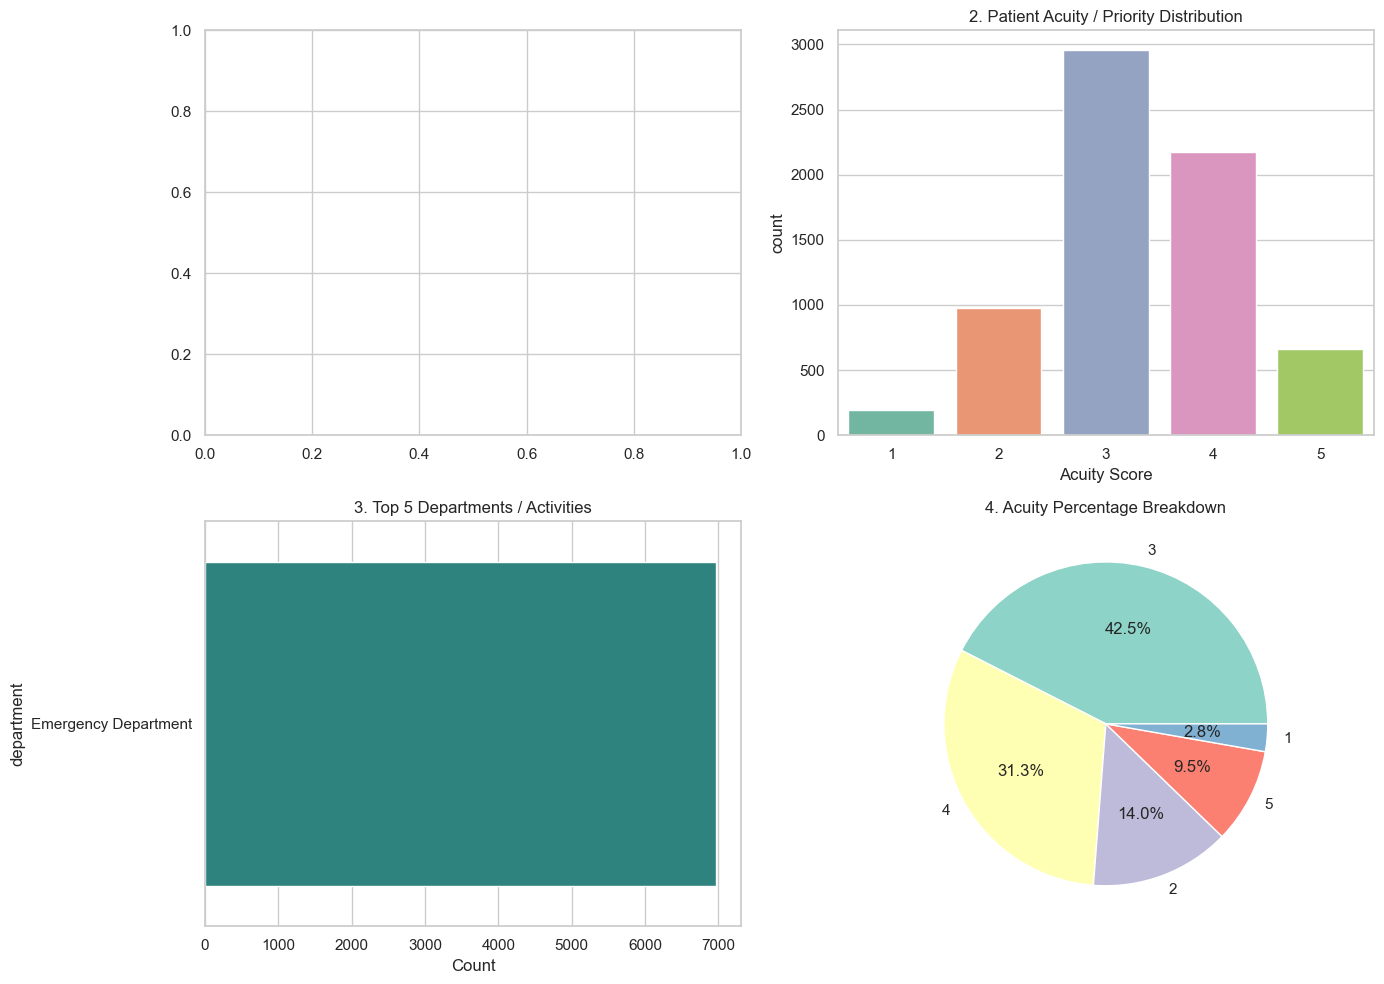

In [2]:
# Create a figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Patient Age Distribution
if "age" in df.columns or "Age" in df.columns:
    age_col = "age" if "age" in df.columns else "Age"
    sns.histplot(df[age_col], kde=True, ax=axes[0, 0], color="skyblue")
    axes[0, 0].set_title("1. Patient Age Distribution")
    axes[0, 0].set_xlabel("Age")

# 2. Acuity / Priority Level Breakdown
if "acuity" in df.columns or "Acuity" in df.columns or "priority" in df.columns:
    acuity_col = [c for c in df.columns if c.lower() in ["acuity", "priority", "triage"]][0]
    sns.countplot(x=df[acuity_col], ax=axes[0, 1], palette="Set2")
    axes[0, 1].set_title("2. Patient Acuity / Priority Distribution")
    axes[0, 1].set_xlabel("Acuity Score")

# 3. Department / Activity Frequencies
if "department" in df.columns or "activity_name" in df.columns:
    dept_col = "department" if "department" in df.columns else "activity_name"
    top_depts = df[dept_col].value_counts().head(5)
    sns.barplot(x=top_depts.values, y=top_depts.index, ax=axes[1, 0], palette="viridis")
    axes[1, 0].set_title("3. Top 5 Departments / Activities")
    axes[1, 0].set_xlabel("Count")

# 4. Gender / Categorical Distribution (if available)
gender_cols = [c for c in df.columns if "gender" in c.lower() or "sex" in c.lower()]
if gender_cols:
    sns.countplot(x=df[gender_cols[0]], ax=axes[1, 1], palette="Pastel1")
    axes[1, 1].set_title("4. Gender Distribution")
else:
    # Fallback plot if gender column is absent
    df[acuity_col].value_counts().plot.pie(
        autopct="%1.1f%%", ax=axes[1, 1], colors=sns.color_palette("Set3")
    )
    axes[1, 1].set_title("4. Acuity Percentage Breakdown")
    axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()